## Multi-label classification

In [3]:
import numpy as np
import pandas as pd
emb = pd.read_csv("../embeddings_par_genre_all.csv", index_col=["genre", "artiste", "titre", "position"])

In [23]:
e = emb.reset_index()

# genres de chaque artiste, triés du plus représentatif (position 0) au moins
tri = e.sort_values("position", kind="stable").drop_duplicates(["artiste", "genre"])
genres_par_artiste = tri.groupby("artiste")["genre"].apply(list).to_dict()

# vérification : un seul genre en position 0 par artiste (doit afficher 0)
p0 = e[e["position"] == 0]
print((p0.groupby("artiste")["genre"].nunique() > 1).sum())

C:\Users\LOZAY\AppData\Local\Temp\ipykernel_12804\4166150746.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  e = emb.reset_index()


0


In [24]:
mask = emb.index.get_level_values("position") == 0 
X_vals = emb[mask].to_numpy()
g = emb.index.get_level_values("artiste")[mask].to_numpy()
principal = {a: gl[0] for a, gl in genres_par_artiste.items()}

from sklearn.preprocessing import MultiLabelBinarizer
mlb = MultiLabelBinarizer()
Y = mlb.fit_transform([genres_par_artiste[a] for a in g]) 
print(X_vals.shape, Y.shape)
print(Y[0,:])

(14325, 768) (14325, 43)
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0
 0 0 0 0 0 0]


In [29]:
art_uniques = pd.unique(g)
Yart = mlb.transform([genres_par_artiste[a] for a in art_uniques])
n_art = pd.Series(Yart.sum(axis=0), index=mlb.classes_).sort_values()
print(n_art)

Alternative            1
Alternative Rock       1
Ambient                1
Avant-garde Black      1
Celtic Folk            1
Crossover              1
Darkwave               1
Death 'n' Roll         1
Glam                   1
Epic Doom              1
Extreme Gothic         1
Epic Heavy             1
Melodic Groove         1
Industrial             1
Melodic Black          1
Hardcore               1
Neoclassical           1
Neoclassical Power     1
Various                1
core                   1
Shred                  1
Sludge                 1
Symphonic Black        1
Nu-                    1
NWOBHM                 2
Noisecore              2
Melodic Death          2
Hardcore Punk          2
Melodic Power          3
Melodic Heavy          3
Doom                   3
Black                  3
Groove                 4
Gothic                 5
Progressive            6
Rock                   6
Grindcore              7
Speed                  8
Hard Rock             11
Thrash                12


In [30]:
garde = n_art[n_art >= 4].index
cols_ok = [i for i, c in enumerate(mlb.classes_) if c in garde]
Y = Y[:, cols_ok]
classes = mlb.classes_[cols_ok]

ok = Y.sum(axis=1) > 0                 # lignes qui gardent au moins un label
X_vals, Y, g = X_vals[ok], Y[ok], g[ok]

In [31]:
print(X_vals.shape, Y.shape, g.shape)
print(classes)

(12729, 768) (12729, 11) (12729,)
['Death' 'Gothic' 'Grindcore' 'Groove' 'Hard Rock' 'Heavy' 'Power'
 'Progressive' 'Rock' 'Speed' 'Thrash']


In [48]:
from sklearn.model_selection import StratifiedGroupKFold

groups = g
freq = n_art.to_dict()     # nombre d'artistes par label
y_strat_rare = np.array([min((x for x in genres_par_artiste[a] if x in garde),
                             key=lambda x: freq[x]) for a in g])

sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True)
dev_idx, test_idx = next(sgkf_test.split(X_vals, y_strat, groups=groups))

X_dev,  Y_dev,  g_dev,  s_dev  = X_vals[dev_idx],  Y[dev_idx],  groups[dev_idx],  y_strat[dev_idx]
X_test, Y_test, g_test, s_test = X_vals[test_idx], Y[test_idx], groups[test_idx], y_strat[test_idx]

sgkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf_val.split(X_dev, s_dev, groups=g_dev))

X_train, Y_train, g_train = X_dev[train_idx], Y_dev[train_idx], g_dev[train_idx]
X_val,   Y_val,   g_val   = X_dev[val_idx],   Y_dev[val_idx],   g_dev[val_idx]

In [49]:
for nom, Yk in [("train", Y_train), ("val", Y_val), ("dev", Y_dev), ("test", Y_test)]:
    print(nom, "labels absents :", list(classes[Yk.sum(axis=0) == 0]))

props = pd.DataFrame({
    "train_%": Y_train.mean(axis=0) * 100,
    "val_%":   Y_val.mean(axis=0) * 100,
    "test_%":  Y_test.mean(axis=0) * 100,
}, index=classes).round(1)
print(props)

train labels absents : []
val labels absents : []
dev labels absents : []
test labels absents : []
             train_%  val_%  test_%
Death           26.8   17.2     6.7
Gothic           7.1    8.1     6.9
Grindcore       13.2    6.6     9.0
Groove           5.4    6.3     8.3
Hard Rock       20.5    7.0    19.1
Heavy           48.0   33.7    34.3
Power           25.8   38.7    21.9
Progressive      7.5    7.5    14.5
Rock             7.9    8.1    14.5
Speed           10.0   19.0    21.9
Thrash          20.3   21.6     8.3


In [50]:
def artistes_par_label(Yk, gk):
    d = pd.DataFrame(Yk, columns=classes)
    d["artiste"] = gk
    return d.groupby("artiste").max().sum(axis=0)    # 1 si l'artiste a le label

art_tab = pd.DataFrame({
    "train": artistes_par_label(Y_train, g_train),
    "val":   artistes_par_label(Y_val, g_val),
    "test":  artistes_par_label(Y_test, g_test),
}).astype(int)
print(art_tab)

             train  val  test
Death           10    2     1
Gothic           3    1     1
Grindcore        5    1     1
Groove           2    1     1
Hard Rock        7    1     3
Heavy           17    4     4
Power            9    5     3
Progressive      3    1     2
Rock             3    1     2
Speed            3    2     3
Thrash           8    3     1


In [67]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score

modele = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced")),
)

res = {"zéro": [], "tout=1": [], "aléatoire": [], "modèle": []}
rng = np.random.default_rng(0)

for train, valid in sgkf.split(X_vals, y_strat, groups=g):
    Yv = Y[valid]

    # 1. tout à 0
    P_zero = np.zeros_like(Yv)

    # 2. tout à 1
    P_un = np.ones_like(Yv)

    # 3. aléatoire selon la fréquence de chaque genre dans le train
    freq = Y[train].mean(axis=0)
    P_rnd = (rng.random(Yv.shape) < freq).astype(int)

    # 4. le modèle
    modele.fit(X_vals[train], Y[train])
    P_mod = modele.predict(X_vals[valid])

    for nom, P in [("zéro", P_zero), ("tout=1", P_un),
                   ("aléatoire", P_rnd), ("modèle", P_mod)]:
        res[nom].append(f1_score(Yv, P, average="macro", zero_division=0))

for nom, v in res.items():
    print(f"{nom:10s} moyenne = {np.mean(v):.3f}  écart-type = {np.std(v):.3f}")

zéro       moyenne = 0.000  écart-type = 0.000
tout=1     moyenne = 0.270  écart-type = 0.029
aléatoire  moyenne = 0.155  écart-type = 0.013
modèle     moyenne = 0.318  écart-type = 0.037


In [69]:
Y_vrai = np.zeros_like(Y)
P_all = np.zeros_like(Y)
proba_all = np.zeros(Y.shape)

for train, valid in sgkf.split(X_vals, y_strat, groups=g):
    modele.fit(X_vals[train], Y[train])
    P_all[valid] = modele.predict(X_vals[valid])
    proba_all[valid] = modele.predict_proba(X_vals[valid])
    Y_vrai[valid] = Y[valid]

             précision  rappel    F1  support
Rock              0.10    0.22  0.14     1179
Groove            0.12    0.21  0.15      785
Progressive       0.17    0.33  0.23     1135
Hard Rock         0.20    0.28  0.24     2227
Gothic            0.22    0.28  0.25      922
Thrash            0.24    0.40  0.30     2310
Speed             0.28    0.47  0.35     1814
Death             0.31    0.41  0.35     2648
Power             0.37    0.49  0.42     3514
Grindcore         0.58    0.52  0.55     1401
Heavy             0.62    0.65  0.63     5389


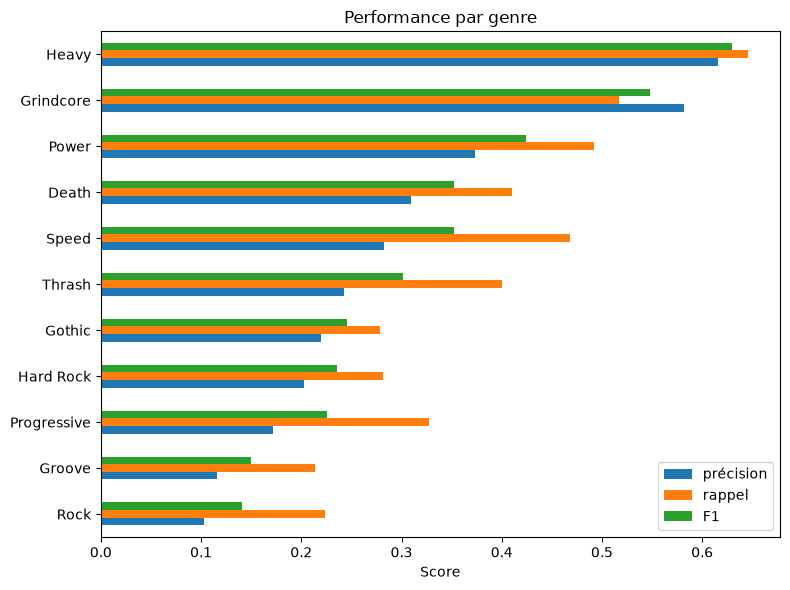

In [71]:
from sklearn.metrics import precision_recall_fscore_support
p, r, f, support = precision_recall_fscore_support(Y_vrai, P_all, zero_division=0)
tab = pd.DataFrame({"précision": p, "rappel": r, "F1": f, "support": support},
                   index=classes).sort_values("F1")
print(tab.round(2))

tab[["précision", "rappel", "F1"]].plot(kind="barh", figsize=(8, 6))
plt.xlabel("Score")
plt.title("Performance par genre")
plt.tight_layout()
plt.show()

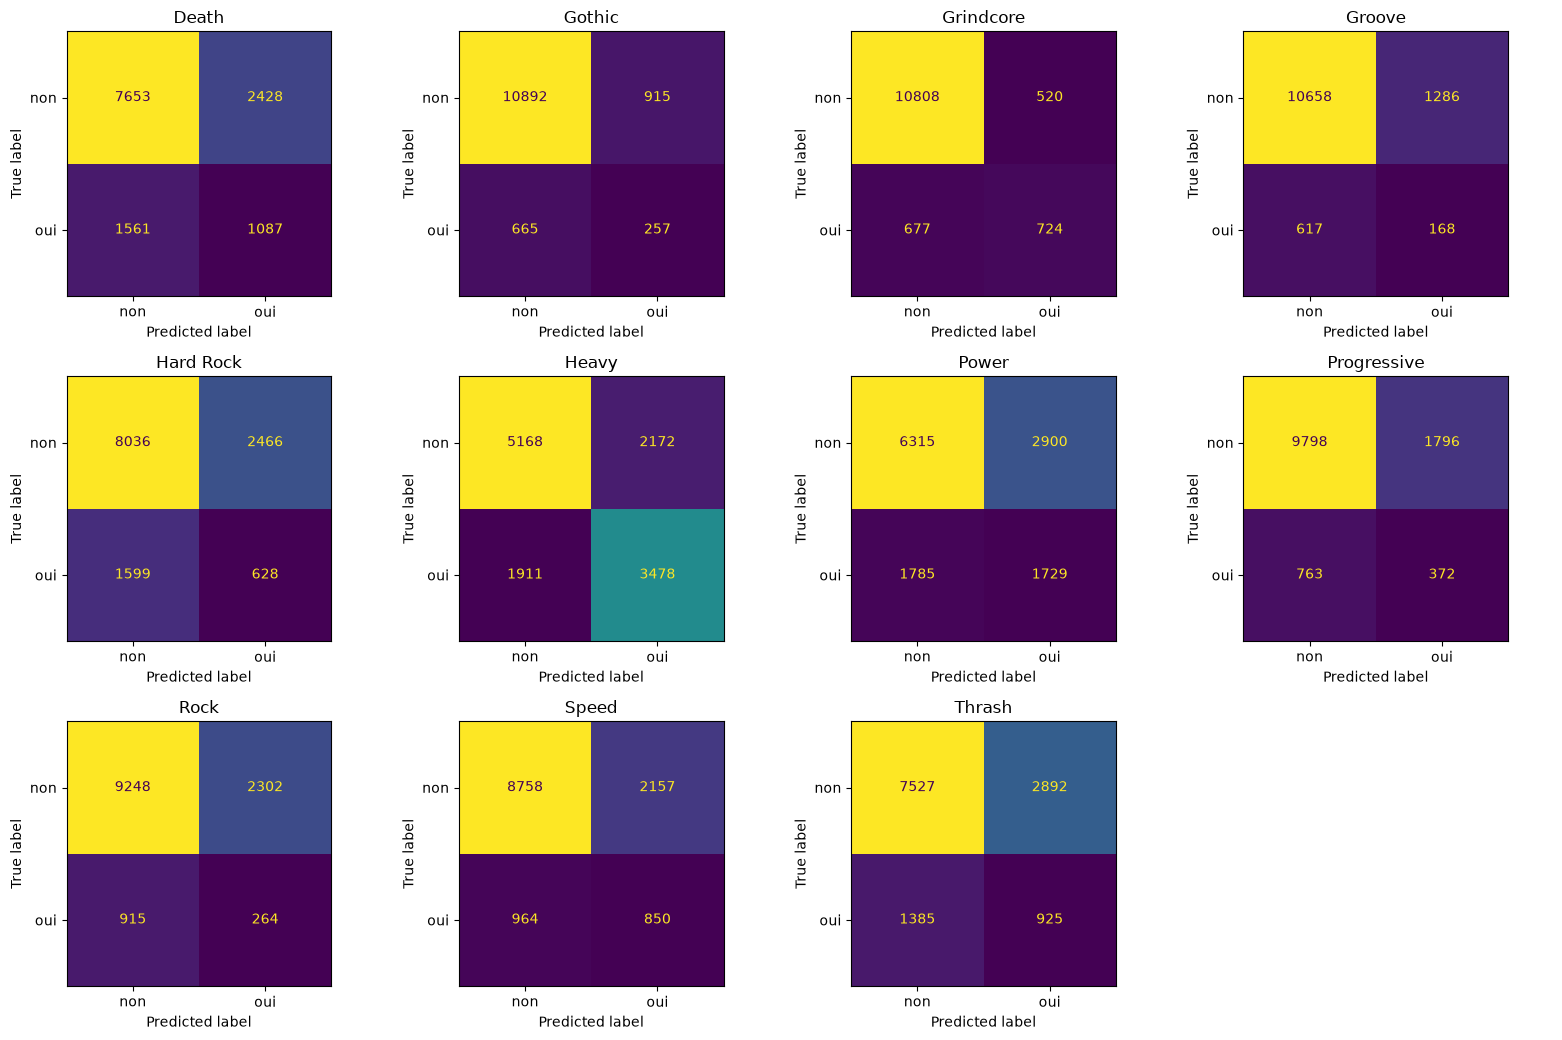

In [72]:
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay

mcm = multilabel_confusion_matrix(Y_vrai, P_all)   # forme (n_genres, 2, 2)

n = len(classes)
cols = 4
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
for ax, m, nom in zip(axes.ravel(), mcm, classes):
    ConfusionMatrixDisplay(m, display_labels=["non", "oui"]).plot(ax=ax, colorbar=False)
    ax.set_title(nom)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Multi-label concatenation de plusieurs classifiers binaires 

In [1]:
import numpy as np
import pandas as pd
emb = pd.read_csv("../embeddings_par_genre_all_1.csv", index_col=["genre", "artiste", "titre", "position"])

In [2]:
seuil = 20  # seuil : nombre minimum d'artistes (exclu)

artistes_par_genre = (
    emb.index.to_frame(index=False)
    .groupby("genre")["artiste"]
    .nunique()
)
genres_ok = artistes_par_genre[artistes_par_genre > seuil].index

print(genres_ok, len(genres_ok))

emb_f = emb[emb.index.get_level_values("genre").isin(genres_ok)]

# X = emb_f
# X_vals = X.to_numpy()
# y = X.index.get_level_values("genre").to_numpy()
# groups = X.index.get_level_values("artiste").to_numpy()
# print(X.shape, y.shape, groups.shape)

Index(['Black', 'Death', 'Doom', 'Folk', 'Gothic', 'Grindcore', 'Groove',
       'Hard Rock', 'Heavy', 'Melodic Death', 'Power', 'Progressive', 'Rock',
       'Speed', 'Symphonic', 'Thrash', 'core'],
      dtype='str', name='genre') 17


In [3]:
# from sklearn.model_selection import StratifiedGroupKFold

# sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
# dev_idx, test_idx = next(sgkf_test.split(X_vals, y, groups=groups))

# X_dev,  y_dev,  g_dev  = X_vals[dev_idx],  y[dev_idx],  groups[dev_idx]
# X_test, y_test, g_test = X_vals[test_idx], y[test_idx], groups[test_idx]

# sgkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
# train_idx, val_idx = next(sgkf_val.split(X_dev, y_dev, groups=g_dev))

# X_train, y_train, g_train = X_dev[train_idx], y_dev[train_idx], g_dev[train_idx]
# X_val,   y_val,   g_val   = X_dev[val_idx],   y_dev[val_idx],   g_dev[val_idx]

In [4]:
# # 1. Aucun groupe commun entre les trois ensembles
# print(set(g_train) & set(g_val))    # doit être vide
# print(set(g_dev)   & set(g_test))   # doit être vide

# # 2. Mêmes genres partout
# print(set(y_train) ^ set(y_val))    # doit être vide
# print(set(y_dev)   ^ set(y_test))   # doit être vide

# # 3. Proportions comparables
# props = pd.DataFrame({
#     "train_%": pd.Series(y_train).value_counts(normalize=True) * 100,
#     "val_%":   pd.Series(y_val).value_counts(normalize=True) * 100,
#     "test_%":  pd.Series(y_test).value_counts(normalize=True) * 100,
# }).fillna(0).round(1)
# print(props)

In [5]:
# from sklearn.preprocessing import StandardScaler
# from sklearn.linear_model import LogisticRegression
# from sklearn.model_selection import GridSearchCV, cross_val_predict
# from sklearn.metrics import precision_recall_curve, f1_score

# scaler = StandardScaler().fit(X_train)
# Xtr = scaler.transform(X_train).astype(np.float32)
# Xva = scaler.transform(X_val).astype(np.float32)

# classes = np.unique(y_train)
# models, thresholds = {}, {}
# proba_val = pd.DataFrame(index=range(len(Xva)), columns=classes, dtype=float)

# for genre in classes:
#     yb = (y_train == genre).astype(int)          # problème binaire pour CE label

#     # CV propre à ce label : stratifiée sur yb, groupée par artiste
#     cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
#     folds = list(cv.split(Xtr, yb, groups=g_train))

#     # 1) choix du C pour ce label
#     gs = GridSearchCV(
#         LogisticRegression(max_iter=2000, class_weight="balanced"),
#         {"C": np.logspace(-3, 2, 6)},
#         cv=folds, scoring="average_precision", n_jobs=-1,
#     ).fit(Xtr, yb)
#     best = gs.best_estimator_

#     # 2) seuil propre à ce label, choisi sur des prédictions out-of-fold (train)
#     oof = cross_val_predict(best, Xtr, yb, cv=folds, method="predict_proba")[:, 1]
#     p, r, t = precision_recall_curve(yb, oof)
#     f1 = 2 * p * r / (p + r + 1e-12)
#     thresholds[genre] = t[np.argmax(f1[:-1])]

#     models[genre] = best
#     proba_val[genre] = best.predict_proba(Xva)[:, 1]

# # prédiction : 1 si la proba du modèle de ce label dépasse son seuil
# Y_pred = pd.DataFrame(
#     {g: (proba_val[g] >= thresholds[g]).astype(int) for g in classes}
# )

In [6]:
# from sklearn.metrics import classification_report

# print(classification_report(Y_val, Y_pred, target_names=classes, zero_division=0))
# print(Y_pred.sum(axis=1).value_counts())   # combien de genres prédits par ligne

In [7]:
# import numpy as np
# import matplotlib.pyplot as plt

# Yv = Y_val.to_numpy()
# Yp = Y_pred.to_numpy()
# support = np.maximum(Yv.sum(axis=0), 1)            # nb de lignes par vrai genre

# M = (Yv.T @ Yp) / support[:, None]                 # (K, K)
# aucun = (((Yp.sum(axis=1) == 0)[:, None]) * Yv).sum(axis=0) / support
# M = np.column_stack([M, aucun])                    # colonne "aucun genre prédit"

# labels = list(classes)
# fig, ax = plt.subplots(figsize=(0.7 * len(labels) + 3, 0.7 * len(labels) + 2))
# im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
# ax.set_xticks(range(len(labels) + 1))
# ax.set_xticklabels(labels + ["aucun"], rotation=45, ha="right")
# ax.set_yticks(range(len(labels)))
# ax.set_yticklabels(labels)
# ax.set_xlabel("Genre prédit (le modèle a répondu 1)")
# ax.set_ylabel("Vrai genre")
# for i in range(M.shape[0]):
#     for j in range(M.shape[1]):
#         ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
#                 color="white" if M[i, j] > 0.5 else "black", fontsize=8)
# fig.colorbar(im, ax=ax)
# plt.tight_layout()
# plt.show()

In [8]:
idx = emb_f.index.to_frame(index=False)
cle = ["artiste", "titre"]      # identifie la chanson, sans genre ni position

# Y : une ligne par chanson, un 1 par genre associé
Y_df = pd.crosstab([idx[c] for c in cle], idx["genre"]).clip(upper=1)

# X : une seule ligne par chanson (l'embedding est identique d'une ligne à l'autre)
base = emb_f.index.droplevel(["genre", "position"])
mask = ~base.duplicated()
X_u = emb_f[mask]
X_u.index = base[mask]

Y_df = Y_df.reindex(X_u.index)
X_vals = X_u.to_numpy()
Y = Y_df.to_numpy()
classes = Y_df.columns.to_numpy()
groups = X_u.index.get_level_values("artiste").to_numpy()

print(X_vals.shape, Y.shape)
print(pd.Series(Y.sum(axis=1)).value_counts().sort_index())   # doit montrer des chansons à 2, 3... genres

(48342, 768) (48342, 17)
1.0    23201
2.0    17323
3.0     6468
4.0     1024
5.0      325
Name: count, dtype: int64


In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, classification_report

# 0) Retirer les lignes sans aucun genre (au cas où)
keep = Y.sum(axis=1) > 0
X_vals, Y, groups = X_vals[keep], Y[keep], groups[keep]

# 1) Split train / val par artiste (aucun artiste dans les deux)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
tr, va = next(gss.split(X_vals, Y, groups=groups))

X_train, X_val = X_vals[tr], X_vals[va]
Y_train, Y_val = Y[tr], Y[va]
g_train = groups[tr]

print(X_train.shape, Y_train.shape, X_val.shape, Y_val.shape)

# 2) Vérifier que chaque genre est présent dans train ET val
print(pd.DataFrame({
    "train": Y_train.sum(axis=0),
    "val": Y_val.sum(axis=0),
}, index=classes).sort_values("val"))

# 3) OvR : un classifieur logistique par colonne de Y
clf = Pipeline([
    ("scale", StandardScaler()),
    ("ovr", OneVsRestClassifier(
        LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced'),
        n_jobs=-1,
    )),
])
clf.fit(X_train, Y_train)

# 4) Prédictions
Y_proba = pd.DataFrame(clf.predict_proba(X_val), columns=classes)
Y_pred = pd.DataFrame(clf.predict(X_val), columns=classes)

# 5) Évaluation
print("F1 macro  :", f1_score(Y_val, Y_pred, average="macro", zero_division=0))
print("F1 samples:", f1_score(Y_val, Y_pred, average="samples", zero_division=0))
print(classification_report(Y_val, Y_pred, target_names=classes, zero_division=0))

# 6) Nombre de genres par chanson : vérité vs prédiction
print(pd.concat({
    "vrai": pd.Series(Y_val.sum(axis=1)).value_counts().sort_index(),
    "prédit": pd.Series(Y_pred.to_numpy().sum(axis=1)).value_counts().sort_index(),
}, axis=1).fillna(0).astype(int))

(38830, 768) (38830, 17) (9511, 768) (9511, 17)
                train     val
core           2394.0   318.0
Melodic Death  3446.0   334.0
Doom           2923.0   397.0
Symphonic      1482.0   401.0
Gothic         3035.0   431.0
Groove         3392.0   577.0
Grindcore      2465.0   618.0
Black          4047.0   674.0
Folk           1612.0   690.0
Rock           2525.0   845.0
Speed          1482.0  1054.0
Thrash         7084.0  1085.0
Progressive    2434.0  1229.0
Hard Rock      3215.0  1327.0
Power          8139.0  1723.0
Death          7751.0  1798.0
Heavy          9010.0  3035.0
F1 macro  : 0.1605215783685137
F1 samples: 0.17258628924393643
               precision    recall  f1-score   support

        Black       0.08      0.39      0.13       674
        Death       0.20      0.45      0.27      1798
         Doom       0.06      0.45      0.10       397
         Folk       0.07      0.23      0.11       690
       Gothic       0.05      0.37      0.09       431
    Grindcore     

In [10]:
from sklearn.metrics import roc_auc_score, average_precision_score

proba = clf.predict_proba(X_val)
auc = [roc_auc_score(Y_val[:, k], proba[:, k]) for k in range(len(classes))]
ap = [average_precision_score(Y_val[:, k], proba[:, k]) for k in range(len(classes))]
print(pd.DataFrame({"auc": auc, "AP": ap, "prevalence": Y_val.mean(axis=0)}, index=classes).round(3))

# surapprentissage : comparer train et val
print("AUC train:", np.mean([roc_auc_score(Y_train[:, k], clf.predict_proba(X_train)[:, k]) for k in range(len(classes))]))
print("AUC val  :", np.mean(auc))

                 auc     AP  prevalence
Black          0.527  0.085       0.071
Death          0.514  0.187       0.189
Doom           0.591  0.053       0.042
Folk           0.482  0.069       0.073
Gothic         0.528  0.049       0.045
Grindcore      0.488  0.064       0.065
Groove         0.535  0.063       0.061
Hard Rock      0.523  0.143       0.140
Heavy          0.518  0.326       0.319
Melodic Death  0.547  0.038       0.035
Power          0.517  0.190       0.181
Progressive    0.508  0.129       0.129
Rock           0.530  0.096       0.089
Speed          0.538  0.123       0.111
Symphonic      0.532  0.043       0.042
Thrash         0.532  0.122       0.114
core           0.500  0.035       0.033
AUC train: 0.7644023077037404
AUC val  : 0.5240176255301644


In [11]:
# for C in [1e-4, 1e-3, 1e-2, 1e-1]:
#     clf = Pipeline([
#         ("scale", StandardScaler()),
#         ("ovr", OneVsRestClassifier(
#             LogisticRegression(C=C, max_iter=2000), n_jobs=-1)),
#     ]).fit(X_train, Y_train)
#     P = clf.predict_proba(X_val)
#     auc = np.mean([roc_auc_score(Y_val[:, k], P[:, k]) for k in range(len(classes))])
#     print(f"C={C:g}  AUC val = {auc:.3f}")

In [12]:
for s in [0.5, 0.6, 0.7, 0.8, 0.9]:
    Yp = (Y_proba.to_numpy() >= s)
    n_pred = Yp.sum()
    prec = (Yp & (Y_val == 1)).sum() / max(n_pred, 1)
    print(f"seuil={s}  prédictions={n_pred}  précision globale={prec:.3f}  (base={Y_val.mean():.3f})")

seuil=0.5  prédictions=57487  précision globale=0.117  (base=0.102)
seuil=0.6  prédictions=33268  précision globale=0.108  (base=0.102)
seuil=0.7  prédictions=17263  précision globale=0.095  (base=0.102)
seuil=0.8  prédictions=7278  précision globale=0.083  (base=0.102)
seuil=0.9  prédictions=1997  précision globale=0.078  (base=0.102)


In [14]:
import numpy as np
import pandas as pd

def relative_threshold_predictions(P, r=0.8, k_max=5, freq=None):
    """
    P     : probabilités (n, K)
    r     : fraction du max de la chanson (0 < r <= 1) ; plus r est haut, moins il y a de labels
    k_max : nombre maximal de labels par chanson
    freq  : fréquence de chaque genre dans le train, pour normaliser les colonnes
    """
    P = np.asarray(P, dtype=float)
    if freq is not None:
        P = P / np.asarray(freq)                  # rend les colonnes comparables

    mx = P.max(axis=1, keepdims=True)
    keep = P >= r * mx                            # au moins 1 : le max passe toujours (r <= 1)

    # plafond : parmi les genres retenus, on ne garde que les k_max plus forts
    rang = np.argsort(-P, axis=1).argsort(axis=1) # rang de chaque genre dans la chanson (0 = meilleur)
    keep &= rang < k_max
    return keep.astype(int)

Y_proba = clf.predict_proba(X_val)
Y_pred_rel = pd.DataFrame(
    relative_threshold_predictions(Y_proba, r=0.8, k_max=5, freq=Y_train.mean(axis=0)),
    columns=classes,
)

In [15]:
print(pd.concat({
    "vrai": pd.Series(Y_val.sum(axis=1)).value_counts().sort_index(),
    "prédit": pd.Series(Y_pred_rel.to_numpy().sum(axis=1)).value_counts().sort_index(),
}, axis=1).fillna(0).astype(int))

     vrai  prédit
1.0  4834    5133
2.0  2855    2809
3.0  1559    1045
5.0   263     145
4.0     0     379


In [16]:
print("F1 macro  :", f1_score(Y_val, Y_pred_rel, average="macro", zero_division=0))
print("F1 samples:", f1_score(Y_val, Y_pred_rel, average="samples", zero_division=0))
print(classification_report(Y_val, Y_pred_rel, target_names=classes, zero_division=0))

F1 macro  : 0.059336212038954866
F1 samples: 0.06555967776659608
               precision    recall  f1-score   support

        Black       0.06      0.01      0.01       674
        Death       0.00      0.00      0.00      1798
         Doom       0.05      0.09      0.07       397
         Folk       0.06      0.24      0.09       690
       Gothic       0.04      0.05      0.05       431
    Grindcore       0.08      0.20      0.12       618
       Groove       0.04      0.02      0.03       577
    Hard Rock       0.13      0.04      0.06      1327
        Heavy       0.00      0.00      0.00      3035
Melodic Death       0.05      0.04      0.04       334
        Power       0.00      0.00      0.00      1723
  Progressive       0.14      0.12      0.13      1229
         Rock       0.08      0.08      0.08       845
        Speed       0.12      0.40      0.19      1054
    Symphonic       0.04      0.31      0.07       401
       Thrash       0.00      0.00      0.00      1085

In [17]:
rng = np.random.default_rng(0)
freq = Y_train.mean(axis=0)
n_lab = Y_pred_rel.sum(axis=1).to_numpy()          # même nombre de labels que le modèle
Y_rand = np.zeros_like(Y_val)
for i, n in enumerate(n_lab):
    Y_rand[i, rng.choice(len(classes), size=n, replace=False, p=freq / freq.sum())] = 1

print("F1 macro hasard  :", f1_score(Y_val, Y_rand, average="macro", zero_division=0))
print("F1 macro modèle  :", f1_score(Y_val, Y_pred_rel, average="macro", zero_division=0))

F1 macro hasard  : 0.09418220448086036
F1 macro modèle  : 0.059336212038954866


## Hypothèse d'inter-dépendance des genres

In [20]:
# fréquence du genre dans le split de train
freq = pd.Series(Y_train.mean(axis=0), index=classes)
print(freq.sort_values(ascending=False).round(3))

Heavy            0.232
Power            0.210
Death            0.200
Thrash           0.182
Black            0.104
Melodic Death    0.089
Groove           0.087
Hard Rock        0.083
Gothic           0.078
Doom             0.075
Rock             0.065
Grindcore        0.063
Progressive      0.063
core             0.062
Folk             0.042
Symphonic        0.038
Speed            0.038
dtype: float64


In [18]:
co = pd.DataFrame(Y_train.T @ Y_train, index=classes, columns=classes)
cond = co.div(np.diag(co), axis=0)      # P(colonne | ligne) : "si la chanson est Death, proba d'être Melodic Death"
print(cond.round(2))

               Black  Death  Doom  Folk  Gothic  Grindcore  Groove  Hard Rock  \
Black           1.00   0.22  0.08  0.13    0.05       0.00    0.00       0.00   
Death           0.12   1.00  0.17  0.00    0.15       0.14    0.13       0.00   
Doom            0.11   0.46  1.00  0.00    0.42       0.03    0.00       0.00   
Folk            0.33   0.00  0.00  1.00    0.00       0.00    0.00       0.00   
Gothic          0.07   0.40  0.40  0.00    1.00       0.00    0.00       0.00   
Grindcore       0.00   0.43  0.03  0.00    0.00       1.00    0.03       0.00   
Groove          0.00   0.30  0.00  0.00    0.00       0.02    1.00       0.00   
Hard Rock       0.00   0.00  0.00  0.00    0.00       0.00    0.00       1.00   
Heavy           0.01   0.01  0.04  0.00    0.00       0.01    0.05       0.33   
Melodic Death   0.03   0.09  0.00  0.08    0.05       0.03    0.22       0.00   
Power           0.01   0.01  0.01  0.02    0.00       0.00    0.02       0.07   
Progressive     0.00   0.10 

On considère que 2 genres sont liés si la probabilité d'appartenir à B sachant A est supérieur à la fréquence de A.

- Heavy et Hard Rock
- Heavy et Power
- Death et Thrash
- Thrash et Groove
- Black et Folk
- Melodic Death et Groove
- Melodic Death et core
- Groove et core
- Gothic et Doom
- Gothic et Rock
- Doom et Progressive
- Doom et Rock
- Rock et Progressive
- Rock et Symphonic
- Folk et Symphonic

In [25]:
n = len(Y_train)
co = Y_train.T @ Y_train                    # nb de chansons ayant A et B
p = Y_train.mean(axis=0)
lift = pd.DataFrame(co / n / np.outer(p, p), index=classes, columns=classes) #hypothèse d'indépendance si = 1 alors indépendant si >1 lié si <1 alors les genres s'exclus

paires = (lift.where(np.triu(np.ones(lift.shape, bool), k=1))
              .stack().sort_values(ascending=False))
print(paires.head(20).round(2))

Progressive    Rock             5.41
Doom           Gothic           5.35
Melodic Death  core             4.55
Hard Rock      Heavy            4.04
Gothic         Rock             3.96
Doom           Rock             3.64
Power          Speed            3.62
Rock           Symphonic        3.59
Black          Folk             3.14
Groove         Thrash           2.65
               Melodic Death    2.48
               core             2.41
Death          Doom             2.31
               Grindcore        2.16
Folk           Melodic Death    1.99
Death          Gothic           1.98
Gothic         Symphonic        1.95
Doom           Progressive      1.73
Heavy          Power            1.67
Power          Progressive      1.64
dtype: float64
